In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers, callbacks

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)

SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [2]:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.mnist.load_data()

print("Train original:", x_train_full.shape, y_train_full.shape)
print("Test:", x_test.shape, y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Train original: (60000, 28, 28) (60000,)
Test: (10000, 28, 28) (10000,)


In [3]:
x_train, x_dev, y_train, y_dev = train_test_split(
    x_train_full, y_train_full,
    test_size=0.20,
    random_state=SEED,
    stratify=y_train_full
)

print("Train:", x_train.shape, y_train.shape)
print("Dev:", x_dev.shape, y_dev.shape)
print("Test:", x_test.shape, y_test.shape)

Train: (48000, 28, 28) (48000,)
Dev: (12000, 28, 28) (12000,)
Test: (10000, 28, 28) (10000,)


In [4]:
x_train = x_train.astype("float32") / 255.0
x_dev   = x_dev.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0

print("Rango train:", x_train.min(), x_train.max())

Rango train: 0.0 1.0


In [9]:
def distribucion_clases(y, nombre):
    conteos = np.bincount(y, minlength=10)
    porcentajes = conteos / len(y) * 100
    tabla = pd.DataFrame({
        "digito": np.arange(10),
        "cantidad": conteos,
        "porcentaje": np.round(porcentajes, 2)
    })
    print("\n", nombre)
    display(tabla)
    return tabla

dist_train = distribucion_clases(y_train, "TRAIN")
dist_dev   = distribucion_clases(y_dev, "DEV")
dist_test  = distribucion_clases(y_test, "TEST")


 TRAIN


,digito,cantidad,porcentaje
0,0,4738,9.87
1,1,5394,11.24
2,2,4766,9.93
3,3,4905,10.22
4,4,4674,9.74
5,5,4337,9.04
6,6,4734,9.86
7,7,5012,10.44
8,8,4681,9.75
9,9,4759,9.91



 DEV


,digito,cantidad,porcentaje
0,0,1185,9.88
1,1,1348,11.23
2,2,1192,9.93
3,3,1226,10.22
4,4,1168,9.73
5,5,1084,9.03
6,6,1184,9.87
7,7,1253,10.44
8,8,1170,9.75
9,9,1190,9.92



 TEST


,digito,cantidad,porcentaje
0,0,980,9.80
1,1,1135,11.35
2,2,1032,10.32
3,3,1010,10.10
4,4,982,9.82
5,5,892,8.92
6,6,958,9.58
7,7,1028,10.28
8,8,974,9.74
9,9,1009,10.09


In [6]:
def crear_modelo_baseline(units=128, optimizer=None):
    modelo = keras.Sequential([
        layers.Input(shape=(28, 28)),
        layers.Flatten(),
        layers.Dense(units, activation="relu"),
        layers.Dense(10, activation="softmax")
    ])

    if optimizer is None:
        optimizer = keras.optimizers.Adam(learning_rate=0.001)

    modelo.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return modelo

modelo_base = crear_modelo_baseline()
modelo_base.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
hist_base = modelo_base.fit(
    x_train, y_train,
    validation_data=(x_dev, y_dev),
    epochs=5,
    batch_size=64,
    verbose=1
)

Epoch 1/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9068 - loss: 0.3359 - val_accuracy: 0.9446 - val_loss: 0.1937
Epoch 2/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9569 - loss: 0.1507 - val_accuracy: 0.9577 - val_loss: 0.1479
Epoch 3/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9696 - loss: 0.1056 - val_accuracy: 0.9618 - val_loss: 0.1296
Epoch 4/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9771 - loss: 0.0800 - val_accuracy: 0.9645 - val_loss: 0.1209
Epoch 5/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9818 - loss: 0.0629 - val_accuracy: 0.9657 - val_loss: 0.1165


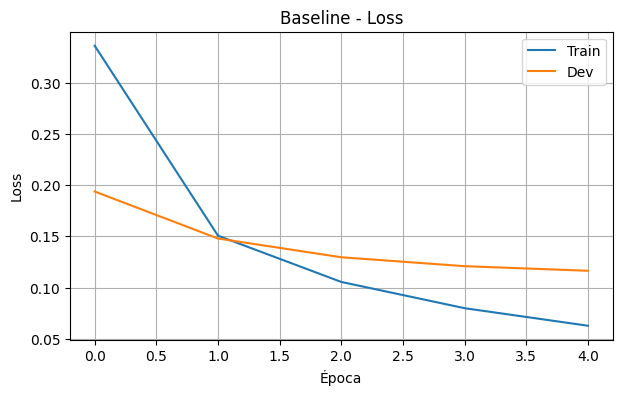

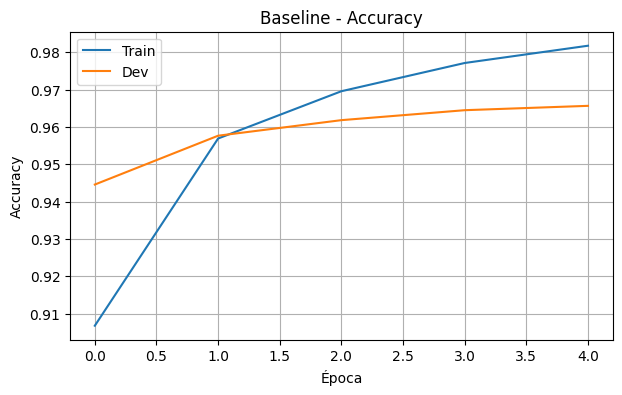

In [8]:
plt.figure(figsize=(7, 4))
plt.plot(hist_base.history["loss"], label="Train")
plt.plot(hist_base.history["val_loss"], label="Dev")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.title("Baseline - Loss")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(hist_base.history["accuracy"], label="Train")
plt.plot(hist_base.history["val_accuracy"], label="Dev")
plt.xlabel("Época")
plt.ylabel("Accuracy")
plt.title("Baseline - Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [10]:
def crear_modelo_experimento(optimizador, units=128):
    modelo = keras.Sequential([
        layers.Input(shape=(28, 28)),
        layers.Flatten(),
        layers.Dense(units, activation="relu"),
        layers.Dense(10, activation="softmax")

    ])
    modelo.compile(
        optimizer=optimizador,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return modelo

In [11]:
fabricas_optimizadores = {
    "SGD_momentum": lambda: keras.optimizers.SGD(
        learning_rate=0.01, momentum=0.9
    ),
    "RMSprop": lambda: keras.optimizers.RMSprop(
        learning_rate=0.001
    ),
    "Adam": lambda: keras.optimizers.Adam(
        learning_rate=0.001
    )
}

resultados_opt = []
historias_opt = {}

for nombre, fabrica in fabricas_optimizadores.items():
    keras.backend.clear_session()
    tf.random.set_seed(SEED)

    modelo = crear_modelo_experimento(fabrica())

    historia = modelo.fit(
        x_train, y_train,
        validation_data=(x_dev, y_dev),
        epochs=5,
        batch_size=64,
        verbose=0
    )

    historias_opt[nombre] = historia
    resultados_opt.append({
        "optimizador": nombre,
        "train_accuracy": historia.history["accuracy"][-1],
        "dev_accuracy": historia.history["val_accuracy"][-1],
        "dev_loss": historia.history["val_loss"][-1]
    })

tabla_opt = pd.DataFrame(resultados_opt)
display(tabla_opt)

,optimizador,train_accuracy,dev_accuracy,dev_loss
0,SGD_momentum,0.966375,0.95575,0.152993
1,RMSprop,0.979875,0.96800,0.109776
2,Adam,0.982292,0.96725,0.113692


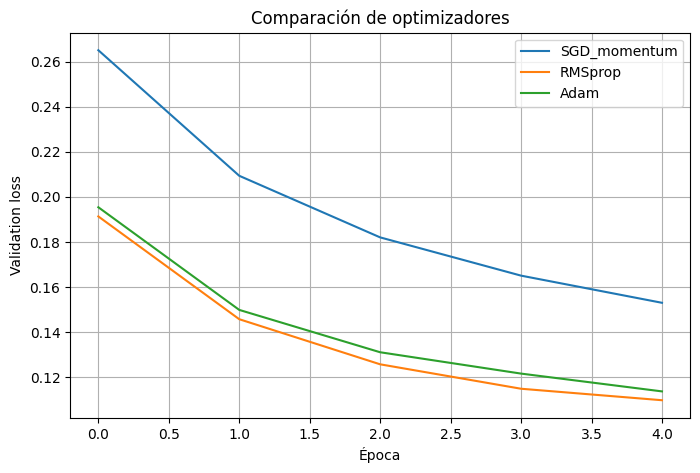

In [12]:
plt.figure(figsize=(8, 5))
for nombre, historia in historias_opt.items():
    plt.plot(historia.history["val_loss"], label=nombre)

plt.xlabel("Época")
plt.ylabel("Validation loss")
plt.title("Comparación de optimizadores")
plt.legend()
plt.grid(True)
plt.show()

In [13]:
learning_rates = [0.0001, 0.001, 0.01]
resultados_lr = []

for lr in learning_rates:
    keras.backend.clear_session()
    tf.random.set_seed(SEED)

    modelo = crear_modelo_experimento(
        keras.optimizers.Adam(learning_rate=lr)
    )

    historia = modelo.fit(
        x_train, y_train,
        validation_data=(x_dev, y_dev),
        epochs=3,
        batch_size=64,
        verbose=0

    )

    resultados_lr.append({
        "learning_rate": lr,
        "train_accuracy": historia.history["accuracy"][-1],
        "dev_accuracy": historia.history["val_accuracy"][-1],
        "dev_loss": historia.history["val_loss"][-1]
    })

display(pd.DataFrame(resultados_lr))

,learning_rate,train_accuracy,dev_accuracy,dev_loss
0,0.0001,0.916188,0.919417,0.288311
1,0.0010,0.969500,0.962417,0.128201
2,0.0100,0.967812,0.958083,0.173259


In [14]:
x_train_reg, _, y_train_reg, _ = train_test_split(
    x_train, y_train,
    train_size=12000,
    random_state=SEED,
    stratify=y_train
)

print("Muestra:", x_train_reg.shape, y_train_reg.shape)

Muestra: (12000, 28, 28) (12000,)


In [15]:
def crear_modelo_sin_regularizacion():
    modelo = keras.Sequential([
        layers.Input(shape=(28, 28)),
        layers.Flatten(),
        layers.Dense(512, activation="relu"),
        layers.Dense(256, activation="relu"),
        layers.Dense(10, activation="softmax")
    ])
    modelo.compile(
        optimizer=keras.optimizers.Adam(0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return modelo

modelo_sin_reg = crear_modelo_sin_regularizacion()
hist_sin_reg = modelo_sin_reg.fit(
    x_train_reg, y_train_reg,
    validation_data=(x_dev, y_dev),
    epochs=15,
    batch_size=64,
    verbose=0
)

In [16]:
def crear_modelo_regularizado():
    modelo = keras.Sequential([
        layers.Input(shape=(28, 28)),
        layers.Flatten(),
        layers.Dense(
            512, activation="relu",
            kernel_regularizer=regularizers.l2(1e-4)
        ),
        layers.Dropout(0.30),
        layers.Dense(
            256, activation="relu",
            kernel_regularizer=regularizers.l2(1e-4)
        ),

        layers.Dropout(0.30),
        layers.Dense(10, activation="softmax")

    ])
    modelo.compile(
        optimizer=keras.optimizers.Adam(0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return modelo

parada_temprana = callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

modelo_reg = crear_modelo_regularizado()
hist_reg = modelo_reg.fit(
    x_train_reg, y_train_reg,
    validation_data=(x_dev, y_dev),
    epochs=20,
    batch_size=64,
    callbacks=[parada_temprana],
    verbose=0
)

print("Épocas ejecutadas:", len(hist_reg.history["loss"]))

Épocas ejecutadas: 8


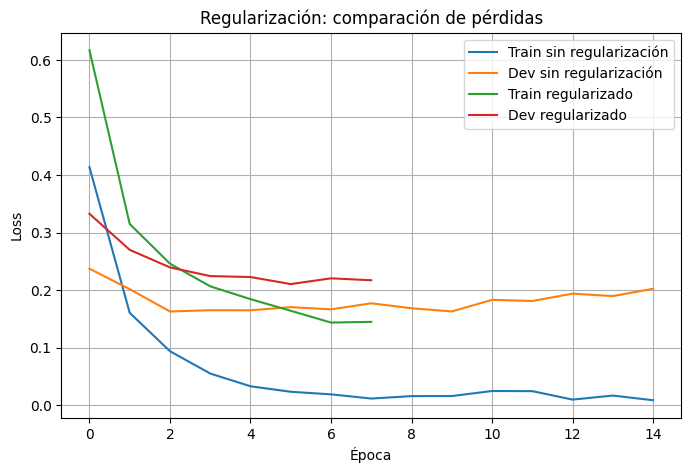

In [19]:
plt.figure(figsize=(8, 5))
plt.plot(hist_sin_reg.history["loss"], label="Train sin regularización")
plt.plot(hist_sin_reg.history["val_loss"], label="Dev sin regularización")
plt.plot(hist_reg.history["loss"], label="Train regularizado")
plt.plot(hist_reg.history["val_loss"], label="Dev regularizado")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.title("Regularización: comparación de pérdidas")
plt.legend()
plt.grid(True)
plt.show()

In [20]:
dev_sin_reg = modelo_sin_reg.evaluate(x_dev, y_dev, verbose=0)
dev_reg = modelo_reg.evaluate(x_dev, y_dev, verbose=0)

print("Sin regularización - dev loss/accuracy:", dev_sin_reg)
print("Regularizado      - dev loss/accuracy:", dev_reg)

Sin regularización - dev loss/accuracy: [0.20214247703552246, 0.9614166617393494]
Regularizado      - dev loss/accuracy: [0.2103145271539688, 0.9629166722297668]


In [21]:
probabilidades_test = modelo_reg.predict(x_test, verbose=0)
y_pred = np.argmax(probabilidades_test, axis=1)

print("Primeras predicciones:", y_pred[:20])
print("Primeras clases reales:", y_test[:20])

Primeras predicciones: [7 2 1 0 4 1 4 9 6 9 0 6 9 0 1 5 9 7 3 4]
Primeras clases reales: [7 2 1 0 4 1 4 9 5 9 0 6 9 0 1 5 9 7 3 4]


In [22]:
accuracy = accuracy_score(y_test, y_pred)
precision_macro = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)
recall_macro = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)
f1_macro = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

print("Accuracy:", round(accuracy, 4))
print("Precision macro:", round(precision_macro, 4))
print("Recall macro:", round(recall_macro, 4))
print("F1 macro:", round(f1_macro, 4))

Accuracy: 0.9649
Precision macro: 0.9645
Recall macro: 0.9648
F1 macro: 0.9646


In [23]:
metricas = pd.DataFrame({
    "metrica": ["Accuracy", "Precision macro", "Recall macro", "F1 macro"],
    "resultado": [accuracy, precision_macro, recall_macro, f1_macro]

})

display(metricas)

,metrica,resultado
0,Accuracy,0.964900
1,Precision macro,0.964538
2,Recall macro,0.964826
3,F1 macro,0.964596


In [24]:
print(
    classification_report(
        y_test, y_pred,
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           0     0.9671    0.9888    0.9778       980
           1     0.9894    0.9833    0.9863      1135
           2     0.9672    0.9438    0.9554      1032
           3     0.9480    0.9743    0.9609      1010
           4     0.9531    0.9735    0.9632       982
           5     0.9534    0.9641    0.9588       892
           6     0.9667    0.9708    0.9688       958
           7     0.9750    0.9484    0.9615      1028
           8     0.9627    0.9548    0.9588       974
           9     0.9627    0.9465    0.9545      1009

    accuracy                         0.9649     10000
   macro avg     0.9645    0.9648    0.9646     10000
weighted avg     0.9650    0.9649    0.9649     10000



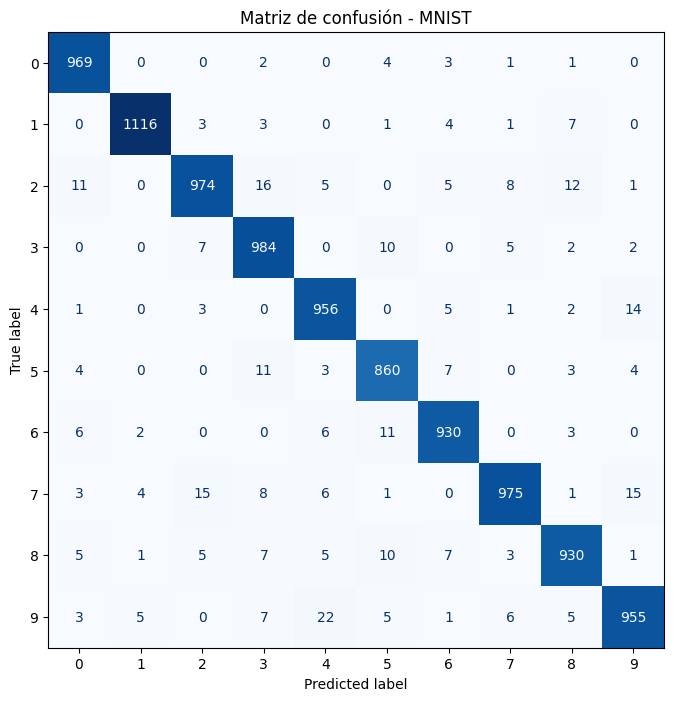

In [25]:
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(8, 8))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(10)
)
disp.plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Matriz de confusión - MNIST")
plt.show()

In [26]:
cm_errores = cm.copy()
np.fill_diagonal(cm_errores, 0)

real_confundido, predicho_como = np.unravel_index(
    np.argmax(cm_errores),
    cm_errores.shape

)

cantidad = cm_errores[real_confundido, predicho_como]

print(
    f"La confusión más frecuente fue: "
    f"{real_confundido} clasificado como {predicho_como} "
    f"({cantidad} veces)"
)

La confusión más frecuente fue: 9 clasificado como 4 (22 veces)


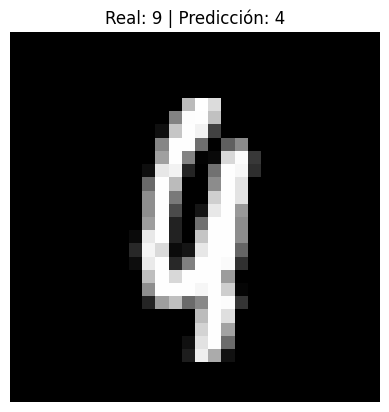

In [27]:
indices = np.where(
    (y_test == real_confundido) &
    (y_pred == predicho_como)
)[0]

if len(indices) > 0:
    idx = indices[0]
    plt.imshow(x_test[idx], cmap="gray")
    plt.title(
        f"Real: {y_test[idx]} | Predicción: {y_pred[idx]}"
    )
    plt.axis("off")
    plt.show()

In [28]:
modelo_pequeno = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(16, activation="relu"),
    layers.Dense(10, activation="softmax")
])

modelo_pequeno.compile(
    optimizer=keras.optimizers.Adam(0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

hist_pequeno = modelo_pequeno.fit(
    x_train, y_train,
    validation_data=(x_dev, y_dev),
    epochs=2,
    batch_size=64,
    verbose=0
)

In [29]:
def resumen_historia(nombre, historia):
    train_acc = historia.history["accuracy"][-1]
    dev_acc = historia.history["val_accuracy"][-1]
    return {
        "modelo": nombre,
        "train_accuracy": train_acc,
        "dev_accuracy": dev_acc,
        "brecha_train_dev": train_acc - dev_acc
    }

tabla_diagnostico = pd.DataFrame([
    resumen_historia("Pequeño", hist_pequeno),
    resumen_historia("Sin regularización", hist_sin_reg),
    resumen_historia("Regularizado", hist_reg)
])

display(tabla_diagnostico)

,modelo,train_accuracy,dev_accuracy,brecha_train_dev
0,Pequeño,0.918750,0.924750,-0.006000
1,Sin regularización,0.997833,0.961417,0.036417
2,Regularizado,0.979750,0.964583,0.015167
